<a href="https://colab.research.google.com/github/hridayrjain/BIS-Lab/blob/main/1BM24CS119_%20Robotics%20and%20automation_%20Grey%20Wolf%20Optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Hriday R Jain


---

1BM24CS119

Application: Robotics and automation

Problem statement: An autonomous robot must travel from a starting position to a target position in an environment containing obstacles. Develop a CS algorithm to optimize the robot's path while avoiding collisions and minimizing travel distance.

Objective: Find a feasible collision-free path with minimum length or travel time.

Executing GWO Grid Environment Path Optimization...
Optimization finished. Best Path Cost: 138.87


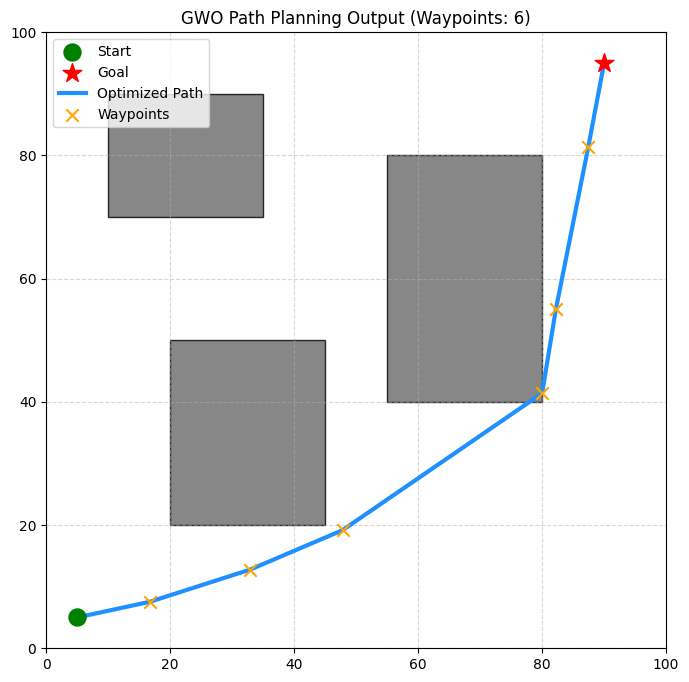

In [1]:
import numpy as np
import matplotlib.pyplot as plt

class GWORobotPathPlanner:
    def __init__(self, start, goal, obstacles, N=30, max_iter=100, n_way=5, grid_size=(100, 100), penalty=1000):
        """
        GWO for Robot Path Planning in a 2D Grid Workspace based exactly on the provided pseudocode template.

        Parameters:
        - start: Tuple (x, y) starting coordinate
        - goal: Tuple (x, y) goal coordinate
        - obstacles: List of dicts, each specifying rectangular bounds: {'x_min', 'x_max', 'y_min', 'y_max'}
        - N: Number of wolves (candidate paths)
        - max_iter: Maximum optimization iterations
        - n_way: Number of intermediate waypoints per path
        - grid_size: Tuple (max_x, max_y) defining workspace boundaries
        - penalty: Multiplier for path collision depth
        """
        self.start = np.array(start, dtype=float)
        self.goal = np.array(goal, dtype=float)
        self.obstacles = obstacles
        self.N = N
        self.max_iter = max_iter
        self.n_way = n_way
        self.grid_size = grid_size
        self.penalty = penalty

        # Dimensions = n_way * 2 (each waypoint has an x and y coordinate)
        self.dim = n_way * 2

        # Step 3: Initialize population (flat array structure for vector math: [x1, y1, x2, y2, ...])
        self.X = np.random.uniform(0, max(grid_size), (self.N, self.dim))

        # Initialize leaders
        self.X_alpha = np.zeros(self.dim)
        self.X_beta = np.zeros(self.dim)
        self.X_delta = np.zeros(self.dim)

        self.f_alpha = float('inf')
        self.f_beta = float('inf')
        self.f_delta = float('inf')

    def _reconstruct_path(self, X_i):
        """Step 1: Path(X) = START + waypoints in X + GOAL"""
        waypoints = X_i.reshape((self.n_way, 2))
        full_path = np.vstack([self.start, waypoints, self.goal])
        return full_path

    def _line_intersects_box(self, p1, p2, box):
        """Calculates collision depth if a path segment passes through a rectangular obstacle."""
        # Fast bounding box check to optimize operations
        if (max(p1[0], p2[0]) < box['x_min'] or min(p1[0], p2[0]) > box['x_max'] or
            max(p1[1], p2[1]) < box['y_min'] or min(p1[1], p2[1]) > box['y_max']):
            return 0.0

        # Sample points along the vector segment to compute penetration depth details
        samples = 15
        collision_depth = 0.0
        for t in np.linspace(0, 1, samples):
            pt = p1 + t * (p2 - p1)
            if (box['x_min'] <= pt[0] <= box['x_max']) and (box['y_min'] <= pt[1] <= box['y_max']):
                # Depth scale determined relative to obstacle boundaries/center
                center_x = (box['x_min'] + box['x_max']) / 2.0
                center_y = (box['y_min'] + box['y_max']) / 2.0
                dist_to_center = np.linalg.norm(pt - np.array([center_x, center_y]))
                collision_depth += max(0.1, 10.0 / (dist_to_center + 0.1))
        return collision_depth

    def fitness(self, X_i):
        """Step 1: f(X) = length(Path(X)) + penalty * collision_depth(Path(X))"""
        path = self._reconstruct_path(X_i)

        # Calculate total Euclidean distance across all path coordinates
        length = np.sum(np.sqrt(np.sum(np.diff(path, axis=0)**2, axis=1)))

        # Calculate structural map collision profile
        total_collision_depth = 0.0
        for i in range(len(path) - 1):
            for obs in self.obstacles:
                total_collision_depth += self._line_intersects_box(path[i], path[i+1], obs)

        return length + (self.penalty * total_collision_depth)

    def optimize(self):
        # Step 4: Initial evaluation of the population
        for i in range(self.N):
            fit = self.fitness(self.X[i])
            if fit < self.f_alpha:
                self.f_delta = self.f_beta; self.X_delta = self.X_beta.copy()
                self.f_beta = self.f_alpha; self.X_beta = self.X_alpha.copy()
                self.f_alpha = fit; self.X_alpha = self.X[i].copy()
            elif fit < self.f_beta:
                self.f_delta = self.f_beta; self.X_delta = self.X_beta.copy()
                self.f_beta = fit; self.X_beta = self.X[i].copy()
            elif fit < self.f_delta:
                self.f_delta = fit; self.X_delta = self.X[i].copy()

        # Step 5 and 6: Update positions and iterate
        for t in range(1, self.max_iter + 1):
            a = 2.0 - 2.0 * (t / self.max_iter)

            for i in range(self.N):
                # Vector arrays to accumulate step profiles from each distinct leader node
                X_steps = []

                for X_L in [self.X_alpha, self.X_beta, self.X_delta]:
                    r1 = np.random.rand(self.dim)
                    r2 = np.random.rand(self.dim)

                    A = 2.0 * a * r1 - a
                    C = 2.0 * r2

                    D = np.abs(C * X_L - self.X[i])
                    X_leaderstep = X_L - A * D
                    X_steps.append(X_leaderstep)

                # X_new = (X_1 + X_2 + X_3) / 3
                X_new = (X_steps[0] + X_steps[1] + X_steps[2]) / 3.0

                # Keep X_new inside the workspace
                X_new = np.clip(X_new, 0, max(self.grid_size))
                self.X[i] = X_new

            # Evaluate f for all wolves & update X_alpha, X_beta, X_delta
            for i in range(self.N):
                fit = self.fitness(self.X[i])
                if fit < self.f_alpha:
                    self.f_delta = self.f_beta; self.X_delta = self.X_beta.copy()
                    self.f_beta = self.f_alpha; self.X_beta = self.X_alpha.copy()
                    self.f_alpha = fit; self.X_alpha = self.X[i].copy()
                elif fit < self.f_beta:
                    self.f_delta = self.f_beta; self.X_delta = self.X_beta.copy()
                    self.f_beta = fit; self.X_beta = self.X[i].copy()
                elif fit < self.f_delta:
                    self.f_delta = fit; self.X_delta = self.X[i].copy()

        # Step 7: Output the best solution
        best_path = self._reconstruct_path(self.X_alpha)
        return best_path, self.f_alpha

    def plot_path(self, best_path):
        """Plots the workspace grid, obstacles, and the optimized waypoint configuration."""
        plt.figure(figsize=(8, 8))
        ax = plt.gca()

        # Plot obstacles
        for obs in self.obstacles:
            rect = plt.Rectangle((obs['x_min'], obs['y_min']),
                                 obs['x_max'] - obs['x_min'],
                                 obs['y_max'] - obs['y_min'],
                                 facecolor='dimgray', edgecolor='black', alpha=0.8)
            ax.add_patch(rect)

        # Plot Start and Goal points
        plt.scatter(self.start[0], self.start[1], color='green', marker='o', s=150, label='Start', zorder=5)
        plt.scatter(self.goal[0], self.goal[1], color='red', marker='*', s=200, label='Goal', zorder=5)

        # Plot optimized path routing configurations
        plt.plot(best_path[:, 0], best_path[:, 1], color='dodgerblue', linestyle='-', linewidth=3, label='Optimized Path')
        plt.scatter(best_path[1:-1, 0], best_path[1:-1, 1], color='orange', marker='x', s=80, label='Waypoints', zorder=4)

        plt.xlim(0, self.grid_size[0])
        plt.ylim(0, self.grid_size[1])
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.title(f"GWO Path Planning Output (Waypoints: {self.n_way})")
        plt.legend(loc='upper left')
        plt.show()

# --- Execution Entry Point ---
if __name__ == "__main__":
    # Define coordinate details
    start_point = (5, 5)
    goal_point = (90, 95)
    bounds = (100, 100)

    # Establish blockades inside grid map
    static_obstacles = [
        {'x_min': 20, 'x_max': 45, 'y_min': 20, 'y_max': 50},
        {'x_min': 55, 'x_max': 80, 'y_min': 40, 'y_max': 80},
        {'x_min': 10, 'x_max': 35, 'y_min': 70, 'y_max': 90}
    ]

    # Instantiate planner matching the user parameter template configurations
    planner = GWORobotPathPlanner(
        start=start_point,
        goal=goal_point,
        obstacles=static_obstacles,
        N=40,            # N = number of wolves
        max_iter=150,     # MaxIter = maximum iterations
        n_way=6,         # n_way = number of waypoints
        grid_size=bounds
    )

    print("Executing GWO Grid Environment Path Optimization...")
    path, fitness_score = planner.optimize()
    print(f"Optimization finished. Best Path Cost: {fitness_score:.2f}")

    # Render final generated visualization figure canvas
    planner.plot_path(path)
